# LendingClub Credit Risk Analysis

LendingClub was a peer-to-peer lending marketplace. Borrowers applied for personal loans; investors funded them and earned the interest. Before listing a loan, LendingClub graded it A–G and set an interest rate to match — riskier grade, higher rate.

This notebook answers two questions.

**Part A — Was the pricing right?**
Did the extra interest charged on risky grades actually compensate investors for the extra defaults? The unit of analysis is the *grade*, not the borrower. The answer is a statement about LendingClub's pricing model.

**Part B — Can default be predicted?**
Using only what a lender knew on application day, can we separate the borrowers who repaid from those who didn't? This is the borrower-level half, and its job is to exploit whatever Part A reveals about mispricing.

They connect: if a grade is priced as one uniform thing but actually contains a mix of risks, a model that finds the good subset earns more than the grade average.

**Requirement:** this notebook must sit in the same folder as `accepted_2007_to_2018Q4.csv.gz`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110

---
# 1. Load the raw data

About 2 minutes. Expect `(2260701, 151)` — 2.26 million loans, 151 columns.

In [2]:
df_raw = pd.read_csv("accepted_2007_to_2018Q4.csv.gz", low_memory=False)
print(df_raw.shape)

(2260701, 151)


## 1.1 What "default" means here

The loan status ladder runs:

`Current` → `In Grace Period` (1–15 days late) → `Late (16–30)` → `Late (31–120)` → `Charged Off`

**Charged Off is the real definition of default.** After roughly 150 days of non-payment LendingClub declares the debt uncollectible and writes it off. Anything recovered afterwards is logged separately in `recoveries`.

In [3]:
print(df_raw["loan_status"].value_counts().to_string())

loan_status
Fully Paid                                             1076751
Current                                                 878317
Charged Off                                             268559
Late (31-120 days)                                       21467
In Grace Period                                           8436
Late (16-30 days)                                         4349
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     40


Two things to notice in those counts.

**The `Default` status covers only ~40 loans platform-wide.** It is a transient state that barely gets used — loans jump from `Late (31–120)` straight to `Charged Off`. We include it in the bad-loan definition for completeness, but it changes nothing.

**The `Does not meet the credit policy` variants (~2,700 loans) are excluded.** These are pre-2010 legacy loans issued under rules LendingClub later abandoned. They fall outside our analysis window anyway.

## 1.2 Default is a partial loss, not a total one

Before interpreting any return figure, it is worth knowing what actually happens to a charged-off loan.

In [4]:
iss = pd.to_datetime(df_raw["issue_d"], format="%b-%Y", errors="coerce")
co_loans = df_raw[(df_raw["loan_status"] == "Charged Off") & iss.between("2012-01-01", "2015-12-31")]

print("charged-off loans (2012-2015):", format(len(co_loans), ","))
print("avg amount lent:      ${:,.0f}".format(co_loans["funded_amnt"].mean()))
print("avg total repaid:     ${:,.0f}".format(co_loans["total_pymnt"].mean()))
print("principal repaid:     {:.1f}%".format(100 * co_loans["total_rec_prncp"].sum() / co_loans["funded_amnt"].sum()))
print("paid nothing at all:  {:.1f}%".format(100 * (co_loans["total_pymnt"] == 0).mean()))
print("loss per $1 lent:     ${:.2f}".format(1 - co_loans["total_pymnt"].sum() / co_loans["funded_amnt"].sum()))

charged-off loans (2012-2015): 146,632
avg amount lent:      $15,618
avg total repaid:     $9,658
principal repaid:     33.2%
paid nothing at all:  0.1%
loss per $1 lent:     $0.38


A charged-off loan recovers roughly a third of its principal. Almost nobody (0.1%) pays nothing at all — the typical defaulter made a year or two of instalments before stopping. So the investor loses about **38 cents on the dollar**, not the whole dollar.

This changes how default rates should be read. A grade defaulting at 40% does not lose investors 40% of their money; it loses roughly 40% × 38% ≈ 15% of principal, which the interest on surviving loans then has to cover.

**Prepayment is the second drag on returns.** Only two loan terms exist (36 and 60 months), but actual duration varies widely because borrowers may repay early with no penalty. Someone who clears a 14% loan in month 6 stops paying interest for the remaining 30 months. So the gap between advertised rate and realised return has two components: default losses and forgone interest. Defaults alone cannot explain why grade A, with only ~5% defaults, returns far below its 7% advertised rate.

---
# 2. Choosing the analysis window

This is a **completed-cohort design** — the same logic as five-year cancer survival, where you cannot include patients diagnosed last year. Every loan must have had enough time to finish before we judge it.

Run the check below rather than taking the window on trust.

In [5]:
chk = df_raw[["issue_d", "loan_status", "term"]].copy()
chk["issue_d"] = pd.to_datetime(chk["issue_d"], format="%b-%Y", errors="coerce")
chk["yr"] = chk["issue_d"].dt.year
chk["term"] = chk["term"].str.strip()
chk["done"] = chk["loan_status"].isin(["Fully Paid", "Charged Off", "Default"])

for t in ["36 months", "60 months"]:
    s = chk[chk["term"] == t]
    g = s.groupby("yr").agg(issued=("done", "size"), matured=("done", "sum"))
    g["pct_matured"] = (g["matured"] / g["issued"] * 100).round(1)
    print(t)
    print(g.loc[2011:2016].to_string())
    print()

36 months
        issued  matured  pct_matured
yr                                  
2011.0   14101    14101        100.0
2012.0   43470    43470        100.0
2013.0  100422   100422        100.0
2014.0  162570   162570        100.0
2015.0  283173   283026         99.9
2016.0  323495   232361         71.8

60 months
        issued  matured  pct_matured
yr                                  
2011.0    7620     7620        100.0
2012.0    9897     9897        100.0
2013.0   34392    34382        100.0
2014.0   73059    60533         82.9
2015.0  137922    92520         67.1
2016.0  110912    60744         54.8



## 2.1 Reading that table

**36-month loans are complete through 2015** — 100%, 100%, 100%, 99.9%.

**60-month loans are complete only through 2013.** Then 82.9% in 2014 and 67.1% in 2015.

A 60-month loan issued in 2014 finishes in 2019, past our December 2018 cutoff, so none should be resolved. The 82.9% that *are* resolved all ended early — either prepaid or defaulted. The rest are still `Current` and get dropped.

**Why that specifically wrecks a return calculation.** Defaults settle in about 150 days; successful repayments take the full five years. So in the 2014–2015 cohorts we count nearly every failure and miss the successes still in progress. Average returns are dragged down, and unevenly — risky grades hold far more 60-month loans, so they take the worst of it.

## 2.2 Two windows, for two purposes

| Purpose | Window | Reason |
|---|---|---|
| **Pricing analysis (Part A)** | 2012–2013 | Both terms 100% matured. ~188k loans. Averages must be unbiased. |
| **Modelling (Part B)** | 2012–2015 | ~786k loans. Bias distorts averages more than it distorts relationships between borrower attributes and default. |

**Why not extend the 60-month window backwards into 2011 and earlier?** It adds only ~10,000 loans from a smaller, differently-run, pre-IPO platform. Section 4.2 shows vintage effects are strong, so mixing in an even earlier regime makes the comparison worse, not better. More data helps only when it is the *same kind* of data.

**Why not use term-specific windows** (36-month from 2012–2015, 60-month from 2012–2013)? Because grade and term are heavily entangled — grade A is ~97% 36-month, grade G is ~97% 60-month. Under that scheme grade A would be measured across 2012–2015 while grade G was measured across 2012–2013 only. Any difference between them would confound grade with vintage, and section 4.2 shows vintage matters enormously.

**A statistically proper alternative**, noted as future work: treat `Current` loans as censored observations and use survival analysis, which handles "survived 30 months, final outcome unknown" correctly. That would let the full 2012–2018 range be used, at the cost of a considerably larger project.

---
# 3. Filter and clean

Keep only loans that **finished** — repaid in full, or written off.

In [6]:
df = df_raw.copy()
df["issue_d"] = pd.to_datetime(df["issue_d"], format="%b-%Y", errors="coerce")

BAD  = ["Charged Off", "Default"]
KEEP = ["Fully Paid"] + BAD

df = df[df["issue_d"].between("2012-01-01", "2015-12-31") & df["loan_status"].isin(KEEP)].copy()
df["target"] = df["loan_status"].isin(BAD).astype(int)
df["issue_yr"] = df["issue_d"].dt.year

print("rows:", format(len(df), ","))
print("default rate: {:.1f}%".format(df["target"].mean() * 100))

rows: 786,820
default rate: 18.6%


In [7]:
for c in ["int_rate", "revol_util"]:
    if df[c].dtype == object:
        df[c] = df[c].str.rstrip("%").astype(float)

df["term"] = df["term"].str.strip()
df["emp_length"] = df["emp_length"].fillna("missing")

# Derived fields for the return analysis
df["term_yrs"]     = df["term"].map({"36 months": 3.0, "60 months": 5.0})
df["total_return"] = (df["total_pymnt"] - df["funded_amnt"]) / df["funded_amnt"]
df["ann_return"]   = df["total_return"] / df["term_yrs"]

print(df[["int_rate", "revol_util", "term", "emp_length", "ann_return"]].head())

   int_rate  revol_util       term emp_length  ann_return
0     13.99        29.7  36 months  10+ years    0.076086
1     11.99        19.2  36 months  10+ years    0.013221
2     10.78        56.2  60 months  10+ years    0.027059
4     22.45        64.5  60 months    3 years    0.025779
5     13.44        68.4  36 months    4 years    0.049064


`emp_length` blanks become their own category rather than being imputed — borrowers who don't state employment length behave differently from those who do, and filling in a guess would erase that.

### Sanity check

Default rate must climb steadily A → G. If it doesn't, something upstream is broken.

In [8]:
print(df.groupby("grade")["target"].agg(n="size", default_rate="mean").round(3))
print()
print(df.groupby("term")["target"].agg(n="size", default_rate="mean").round(3))

            n  default_rate
grade                      
A      136345         0.055
B      229476         0.120
C      217123         0.205
D      120677         0.284
E       59013         0.373
F       19639         0.430
G        4547         0.478

                n  default_rate
term                           
36 months  589488         0.140
60 months  197332         0.324


Term matters enormously on its own — 60-month loans default at roughly double the 36-month rate. That is not only longer exposure: riskier borrowers self-select into longer terms.

---
# 4. Part A — Was the pricing right?

For each finished loan:

```
total return = (total_pymnt - funded_amnt) / funded_amnt
annualised   = total return / term in years
```

`total_pymnt` is everything the borrower ever paid; `funded_amnt` is what was lent. Note that these are *post-outcome* columns — forbidden to the model in Part B, but essential here. The distinction is information timing, not the column itself.

Run this on the clean 2012–2013 window.

In [9]:
clean = df[df["issue_yr"] <= 2013]

def pricing_table(data):
    g = data.groupby("grade").agg(
        n               = ("ann_return", "size"),
        advertised_rate = ("int_rate", "mean"),
        default_rate    = ("target", "mean"),
        realised_return = ("ann_return", "mean"),
    )
    g["advertised_rate"] = g["advertised_rate"].round(2)
    g["default_rate"]    = (g["default_rate"] * 100).round(1)
    g["realised_return"] = (g["realised_return"] * 100).round(2)
    return g

pricing = pricing_table(clean)
pricing

,n,advertised_rate,default_rate,realised_return
grade,,,,
A,28580,7.69,5.7,2.52
B,62622,11.91,11.0,3.51
C,50005,15.48,17.7,3.88
D,27889,18.61,22.7,4.10
E,12244,21.55,29.1,4.29
F,5707,23.77,35.0,3.93
G,1124,25.27,37.4,3.92


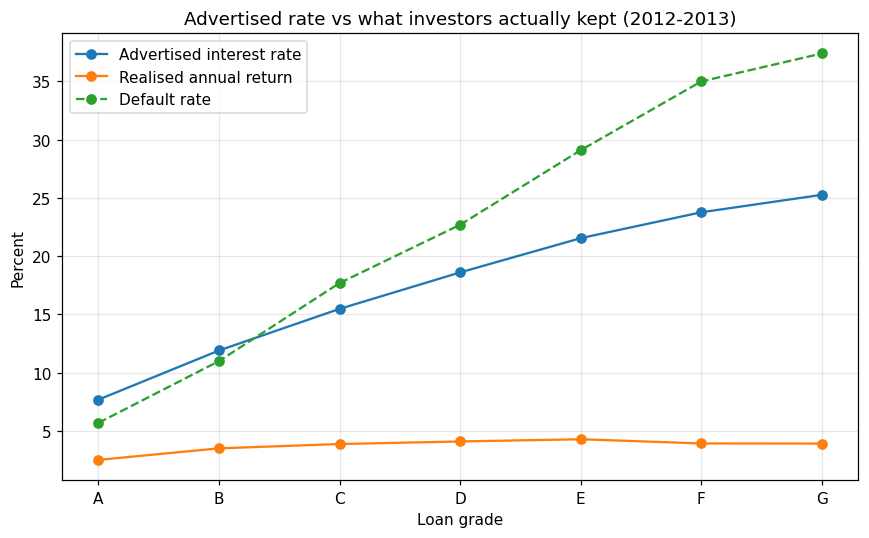

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pricing.index, pricing["advertised_rate"], marker="o", label="Advertised interest rate")
ax.plot(pricing.index, pricing["realised_return"], marker="o", label="Realised annual return")
ax.plot(pricing.index, pricing["default_rate"], marker="o", linestyle="--", label="Default rate")
ax.set_xlabel("Loan grade")
ax.set_ylabel("Percent")
ax.set_title("Advertised rate vs what investors actually kept (2012-2013)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("charts/pricing_gap.png", dpi=150, bbox_inches="tight")
plt.show()

## 4.1 What the clean window shows

Realised returns rise modestly across grades and then flatten — roughly 2.5% for grade A up to about 4.3% for grade E, then level off.

So the risk premium *does* compensate, but barely. An investor in grade E accepts a ~29% default rate to earn about 4.3%; an investor in grade A accepts ~6% to earn about 2.5%. That is a small reward for enormously more risk and variance, and on a risk-adjusted basis it is unattractive.

**The more striking gap is vertical, not horizontal.** Every grade returns far below its advertised rate — grade A advertises ~7% and delivers ~2.5%. Defaults alone cannot explain that for grade A. Prepayment does: borrowers who repay early stop paying interest, and the investor's capital sits idle.

## 4.2 Why the window choice matters — a methodological check

It is worth showing what happens with a plausible but wrong window, because it produces a dramatic and completely false conclusion.

In [11]:
print("PRICING ON THE CONTAMINATED WINDOW (2012-2015)")
print(pricing_table(df)[["n", "default_rate", "realised_return"]].to_string())
print()
print("PRICING ON THE CLEAN WINDOW (2012-2013)")
print(pricing[["n", "default_rate", "realised_return"]].to_string())

PRICING ON THE CONTAMINATED WINDOW (2012-2015)
            n  default_rate  realised_return
grade                                       
A      136345           5.5             2.35
B      229476          12.0             2.79
C      217123          20.5             2.51
D      120677          28.4             2.14
E       59013          37.3             1.27
F       19639          43.0             1.08
G        4547          47.8             0.28

PRICING ON THE CLEAN WINDOW (2012-2013)
           n  default_rate  realised_return
grade                                      
A      28580           5.7             2.52
B      62622          11.0             3.51
C      50005          17.7             3.88
D      27889          22.7             4.10
E      12244          29.1             4.29
F       5707          35.0             3.93
G       1124          37.4             3.92


On 2012–2015 the returns appear to **collapse** after grade B, falling to near zero by grade G. That reads as a dramatic finding: the risk premium is a mirage.

It is largely an artefact. The 2014–2015 60-month loans are only 67–83% matured, so their fast-resolving defaults are counted while their slow-resolving successes are still `Current` and excluded. Risky grades hold far more 60-month loans, so they absorb nearly all of the distortion.

**This is the single most important methodological point in the project.** A reasonable-looking windowing choice produced a headline that was mostly measurement error. Most analyses of this dataset never run this check.

## 4.3 Grade drift — did a letter mean the same thing over time?

The comparison above mixes maturity bias with a possible real change in loan quality. To separate them, restrict to **36-month loans only**, which are 100% matured across the whole 2012–2015 range. Any difference here cannot be a maturity artefact.

In [12]:
s36 = df[df["term"] == "36 months"]

for lab, sub in [("2012-2013", s36[s36["issue_yr"] <= 2013]),
                 ("2014-2015", s36[s36["issue_yr"] >= 2014])]:
    g = sub.groupby("grade").agg(n=("ann_return", "size"),
                                 default_rate=("target", "mean"),
                                 realised_return=("ann_return", "mean"))
    g["default_rate"]    = (g["default_rate"] * 100).round(1)
    g["realised_return"] = (g["realised_return"] * 100).round(2)
    print(lab)
    print(g.to_string())
    print()

2012-2013
           n  default_rate  realised_return
grade                                      
A      27810           5.6             2.52
B      57118          10.6             3.53
C      34595          15.9             3.90
D      19593          20.6             4.24
E       4026          23.0             4.77
F        711          25.6             4.64
G         39          20.5             5.15

2014-2015
            n  default_rate  realised_return
grade                                       
A      105451           5.4             2.32
B      145185          11.5             2.72
C      121465          18.6             2.52
D       53221          24.7             2.32
E       16509          30.4             1.96
F        3341          34.8             2.44
G         424          42.0             0.56



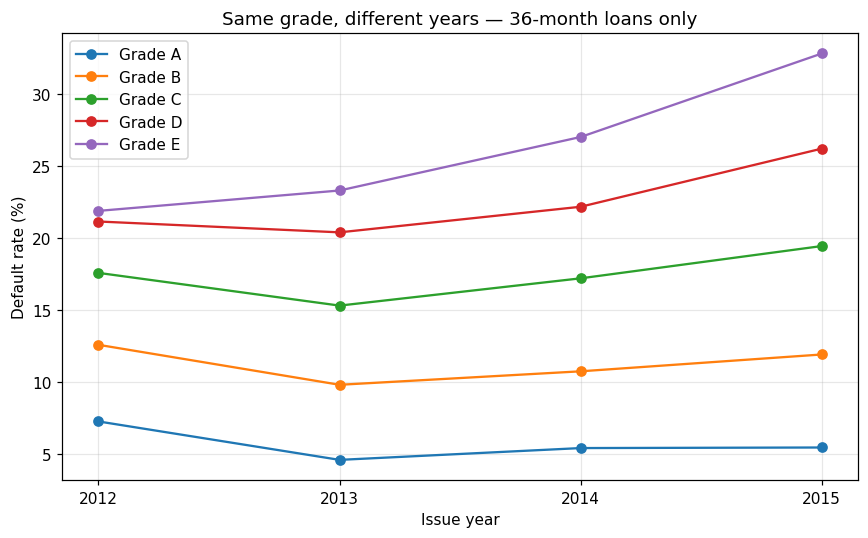

In [13]:
drift = (s36.groupby(["issue_yr", "grade"])["target"].mean() * 100).unstack()

fig, ax = plt.subplots(figsize=(8, 5))
for gr in ["A", "B", "C", "D", "E"]:
    if gr in drift.columns:
        ax.plot(drift.index, drift[gr], marker="o", label="Grade " + gr)
ax.set_xlabel("Issue year")
ax.set_ylabel("Default rate (%)")
ax.set_title("Same grade, different years — 36-month loans only")
ax.set_xticks(drift.index)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("charts/grade_drift.png", dpi=150, bbox_inches="tight")
plt.show()

### The finding

A grade E borrower in 2012-2013 defaulted at about 23%. A grade E borrower in 2014-2015 defaulted at about 30%. Same letter, same term, both cohorts fully resolved — so this is real, not a data artefact.

**The grades drifted.** LendingClub grew from 43,000 loans in 2012 to 283,000 in 2015. Sustaining that growth meant approving borrowers who would have been declined earlier, and they were assigned the same letters. The label stayed constant while the risk behind it rose.

This is arguably a better finding than the pricing table, because it says something about the company rather than about a portfolio. It also has a direct implication for Part B: if grades meant different things in different years, a model built on borrower attributes rather than on the grade should be more stable over time — and that is testable.

---
# 5. Part B — Setting up the prediction problem

## 5.1 The leakage audit

Roughly 40 of the 151 columns are recorded **during or after repayment**: payments received, recoveries, hardship plans, settlement terms. On the day a lender decides whether to approve a loan, none of these exist.

Feed them to a model and it reaches near-perfect accuracy — because `total_pymnt` close to zero simply means "they defaulted." The model has memorised the answer, not predicted it.

Note the asymmetry: those same columns were **required** for Part A. Forbidden in one place, essential in another.

In [14]:
LEAKAGE = [
    "out_prncp", "out_prncp_inv", "total_pymnt", "total_pymnt_inv",
    "total_rec_prncp", "total_rec_int", "total_rec_late_fee",
    "recoveries", "collection_recovery_fee",
    "last_pymnt_d", "last_pymnt_amnt", "next_pymnt_d", "last_credit_pull_d",
    "last_fico_range_high", "last_fico_range_low",
    "debt_settlement_flag", "debt_settlement_flag_date", "settlement_status",
    "settlement_date", "settlement_amount", "settlement_percentage", "settlement_term",
    "hardship_flag", "hardship_type", "hardship_reason", "hardship_status",
    "deferral_term", "hardship_amount", "hardship_start_date", "hardship_end_date",
    "payment_plan_start_date", "hardship_length", "hardship_dpd", "hardship_loan_status",
    "orig_projected_additional_accrued_interest",
    "hardship_payoff_balance_amount", "hardship_last_payment_amount", "pymnt_plan",
]

# Known at origination, but these are LendingClub's OWN risk judgement.
# Held separately so we can measure how much independent signal we find.
PLATFORM = ["grade", "sub_grade", "int_rate", "installment"]

DROP_OTHER = ["id", "member_id", "url", "desc", "title", "emp_title", "zip_code"]
TARGET_SRC = ["loan_status", "target"]
DERIVED    = ["term_yrs", "total_return", "ann_return", "issue_yr"]

def classify(c):
    if c in LEAKAGE:    return "LEAKAGE"
    if c in PLATFORM:   return "PLATFORM"
    if c in DROP_OTHER: return "DROP"
    if c in TARGET_SRC: return "TARGET"
    if c in DERIVED:    return "DERIVED"
    return "REVIEW"

audit = pd.DataFrame({
    "column":      df.columns,
    "bucket":      [classify(c) for c in df.columns],
    "pct_missing": [round(df[c].isna().mean() * 100, 1) for c in df.columns],
    "n_unique":    [df[c].nunique() for c in df.columns],
})

print(audit["bucket"].value_counts())

bucket
REVIEW      101
LEAKAGE      38
DROP          7
PLATFORM      4
DERIVED       4
TARGET        2
Name: count, dtype: int64


In [15]:
audit[audit["bucket"] == "REVIEW"].sort_values("pct_missing", ascending=False).head(40)

,column,bucket,pct_missing,n_unique
115,revol_bal_joint,REVIEW,100.0,0
127,sec_app_mths_since_last_major_derog,REVIEW,100.0,0
126,sec_app_collections_12_mths_ex_med,REVIEW,100.0,0
125,sec_app_chargeoff_within_12_mths,REVIEW,100.0,0
124,sec_app_num_rev_accts,REVIEW,100.0,0
123,sec_app_open_act_il,REVIEW,100.0,0
122,sec_app_revol_util,REVIEW,100.0,0
121,sec_app_open_acc,REVIEW,100.0,0
120,sec_app_mort_acc,REVIEW,100.0,0
119,sec_app_inq_last_6mths,REVIEW,100.0,0


## 5.2 Why is it missing?

The REVIEW columns are not all missing for the same reason, and the reason determines the fix.

In [16]:
check_cols = ["open_acc_6m", "all_util", "il_util", "avg_cur_bal", "mths_since_last_delinq"]
print("pct missing by issue year:")
print(df.groupby(df["issue_d"].dt.year)[check_cols].apply(lambda x: (x.isna().mean() * 100).round(1)))

pct missing by issue year:
         open_acc_6m  all_util  il_util  avg_cur_bal  mths_since_last_delinq
issue_d                                                                     
2012           100.0     100.0    100.0         52.0                    58.8
2013           100.0     100.0    100.0          0.0                    56.5
2014           100.0     100.0    100.0          0.0                    49.1
2015            95.0      95.0     95.6          0.0                    48.3


In [17]:
miss = df[df["mths_since_last_delinq"].isna()]
print("of rows missing mths_since_last_delinq,")
print("  pct with zero delinquencies in last 2y: {:.1f}%".format((miss["delinq_2yrs"] == 0).mean() * 100))
print()
print("default rate:")
print("  missing: {:.2f}%".format(df[df["mths_since_last_delinq"].isna()]["target"].mean() * 100))
print("  present: {:.2f}%".format(df[df["mths_since_last_delinq"].notna()]["target"].mean() * 100))

of rows missing mths_since_last_delinq,
  pct with zero delinquencies in last 2y: 99.5%

default rate:
  missing: 18.08%
  present: 19.21%


### Two different kinds of missing

**Missing by vintage — drop these.** `open_acc_6m`, `all_util`, `il_util` and their neighbours are 100% missing in 2012–2014 and ~95% missing in 2015. LendingClub began collecting them at the very end of the window. So *the presence of a value proxies for issue date*, not for borrower quality. A model trained on it learns "this loan is from December 2015," which is meaningless.

**Missing by meaning — keep these.** About 99.5% of rows missing `mths_since_last_delinq` have zero delinquencies in the last two years. The value is blank because *the event never happened*. That is a clean credit record, not absent data, and it is predictive in the expected direction.

These get encoded as two features each: a flag marking "never happened", plus the original number with a sentinel value.

This distinction — missing-by-vintage versus missing-by-meaning — is the kind of judgement an interviewer will ask you to defend.

---
# 6. Exploratory analysis

The purpose here is not to produce plots. It is to find the borrower attributes that separate repayers from defaulters, which become the features in Part B.

Two helper functions: one bins a numeric variable and shows default rate per bin, the other does the same for categories.

In [18]:
def num_driver(data, col, bins=10, ax=None, clip=0.99):
    """Default rate across quantile bins of a numeric column."""
    s = data[[col, "target"]].dropna()
    s = s[s[col] <= s[col].quantile(clip)]          # trim the tail so bins are readable
    s["bin"] = pd.qcut(s[col], bins, duplicates="drop")
    g = s.groupby("bin", observed=True).agg(default_rate=("target", "mean"), n=("target", "size"))
    g["default_rate"] *= 100
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.bar(range(len(g)), g["default_rate"], color="steelblue")
    ax.axhline(data["target"].mean() * 100, color="crimson", linestyle="--", lw=1, label="overall")
    ax.set_xticks(range(len(g)))
    ax.set_xticklabels([str(round(i.left, 1)) for i in g.index], rotation=45, ha="right", fontsize=7)
    ax.set_title(col, fontsize=10)
    ax.set_ylabel("default %", fontsize=8)
    return g


def cat_driver(data, col, min_n=500):
    """Default rate by category, sorted, dropping tiny groups."""
    g = data.groupby(col).agg(n=("target", "size"), default_rate=("target", "mean"))
    g = g[g["n"] >= min_n].sort_values("default_rate", ascending=False)
    g["default_rate"] = (g["default_rate"] * 100).round(1)
    return g

## 6.1 Numeric drivers

Binned by decile, so the shape of the relationship is visible rather than just a correlation coefficient. The dashed line is the overall default rate.

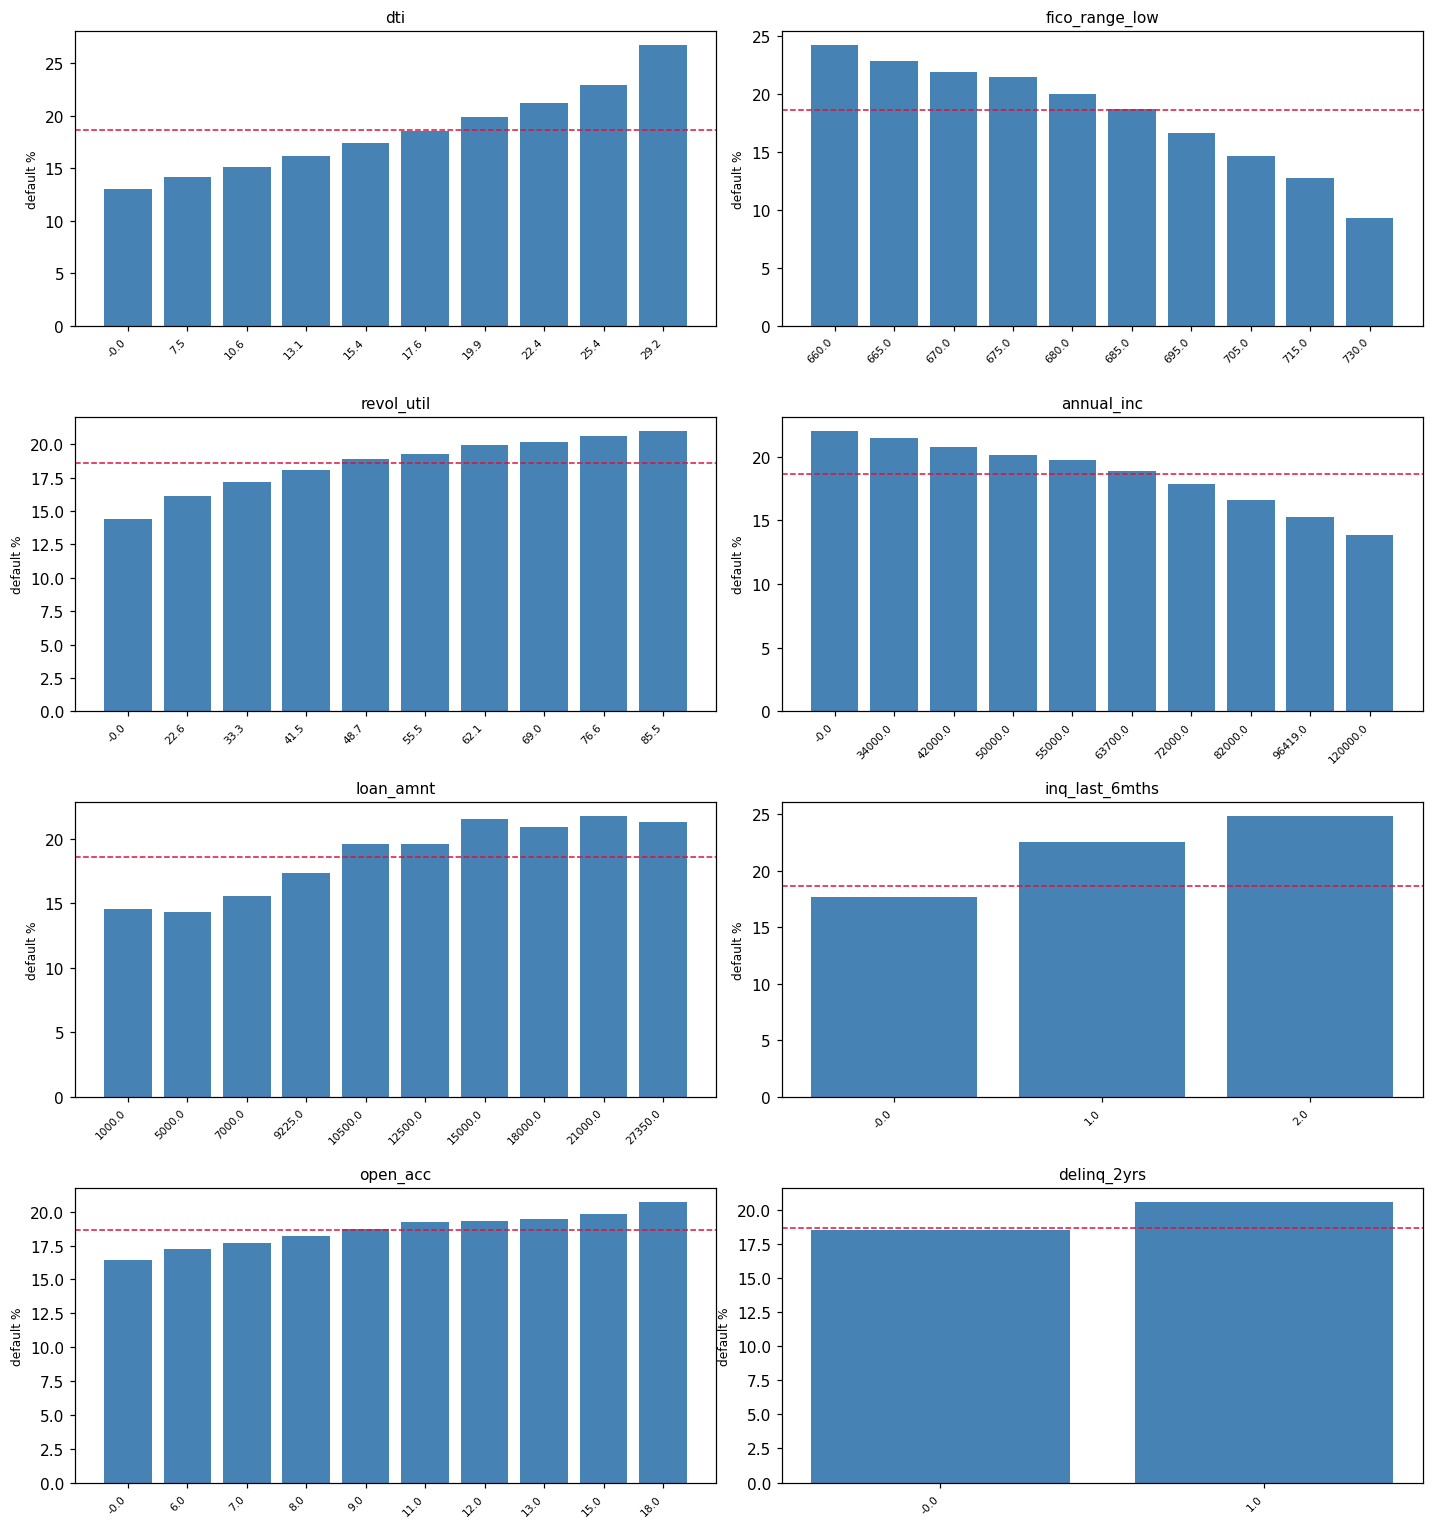

In [19]:
num_cols_eda = ["dti", "fico_range_low", "revol_util", "annual_inc",
                "loan_amnt", "inq_last_6mths", "open_acc", "delinq_2yrs"]

fig, axes = plt.subplots(4, 2, figsize=(13, 14))
for c, ax in zip(num_cols_eda, axes.ravel()):
    num_driver(df, c, ax=ax)
plt.tight_layout()
plt.show()

Read these for **shape**, not just direction:

- **`dti`** (debt-to-income) and **`revol_util`** (how much of the available credit limit is already used) should rise steadily — both measure existing financial strain.
- **`fico_range_low`** should fall sharply. It is the strongest single predictor in most credit datasets.
- **`annual_inc`** typically falls but flattens quickly — income beyond a threshold stops mattering much.
- **`inq_last_6mths`** (recent credit applications) usually rises. Someone shopping for credit everywhere is often in trouble.
- A **monotonic** relationship suits a linear scorecard. A **U-shaped or flat** one signals a variable that needs binning or is weak.

## 6.2 Categorical drivers

In [20]:
for c in ["purpose", "home_ownership", "emp_length", "verification_status", "term"]:
    print(cat_driver(df, c).to_string())
    print()

                         n  default_rate
purpose                                 
small_business        8002          27.1
moving                4640          21.8
house                 3148          21.4
debt_consolidation  468555          19.8
other                36824          19.8
medical               7469          19.7
vacation              4261          17.5
major_purchase       14076          17.2
home_improvement     45310          16.8
credit_card         185814          15.6
car                   6922          14.1
wedding               1343          13.6

                     n  default_rate
home_ownership                      
RENT            316618          21.2
OWN              78358          19.2
MORTGAGE        391753          16.4

                 n  default_rate
emp_length                      
missing      41499          23.7
9 years      30824          19.2
8 years      39462          19.1
< 1 year     61358          19.1
1 year       50242          18.8
7 years 

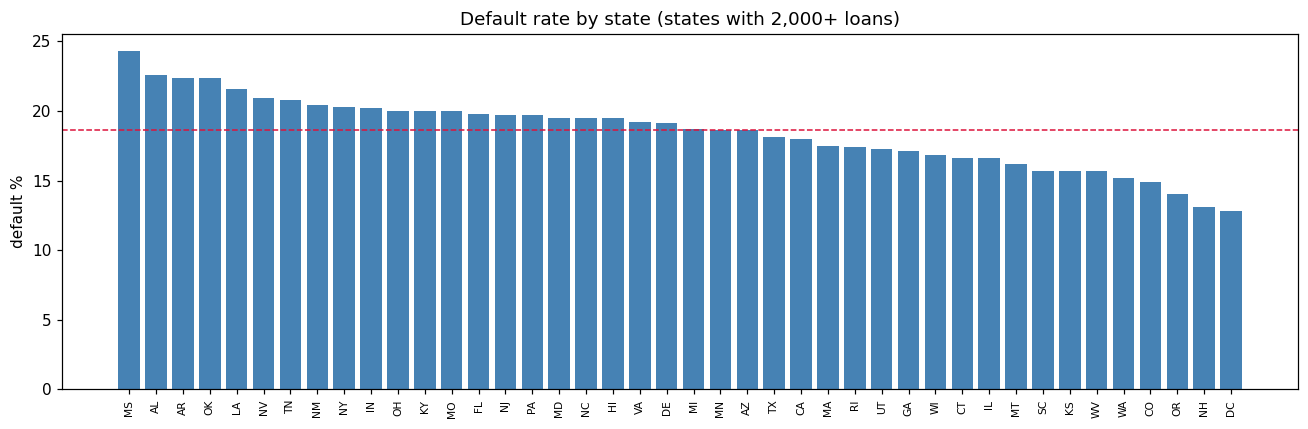

In [21]:
state = cat_driver(df, "addr_state", min_n=2000)
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(state.index, state["default_rate"], color="steelblue")
ax.axhline(df["target"].mean() * 100, color="crimson", linestyle="--", lw=1)
ax.set_title("Default rate by state (states with 2,000+ loans)")
ax.set_ylabel("default %")
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()
plt.show()

Things to look for and comment on:

- **`purpose`** — small business borrowing is consistently the worst category; credit-card refinancing among the best. The stated reason for borrowing carries real signal.
- **`verification_status`** — counter-intuitively, *verified* income often defaults **more** than unverified. LendingClub verified selectively, targeting applications that looked risky. The variable partly encodes their suspicion rather than the borrower's quality. Worth calling out — it is a nice example of a feature that measures the lender's behaviour, not the borrower's.
- **`emp_length`** — check whether the `missing` category behaves differently. That is the justification for having kept it.
- **`addr_state`** — differences are usually modest. Be careful about reading much into small states.

## 6.3 Does the relationship hold across years?

Section 4.3 showed grades drifted. Borrower attributes should be more stable — that is the argument for modelling on attributes rather than on the grade. Worth verifying rather than assuming.

fico_bin  (659.999, 670.0]  (670.0, 680.0]  (680.0, 695.0]  (695.0, 715.0]  (715.0, 845.0]
issue_yr                                                                                  
2012                  20.7            15.9            14.2            11.5             8.2
2013                  16.3            14.7            13.1            10.0             6.3
2014                  17.9            16.0            13.7            11.0             6.8
2015                  19.7            17.7            15.1            11.8             7.4


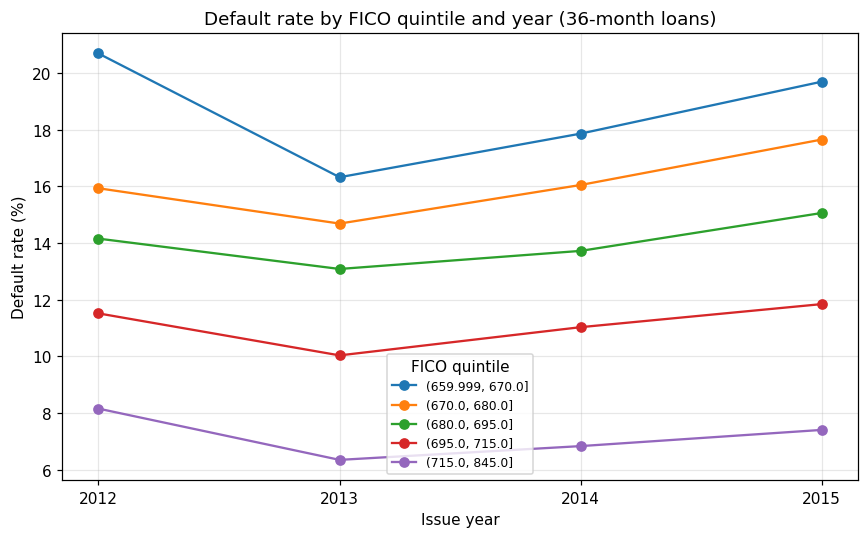

In [22]:
s = s36[["fico_range_low", "dti", "issue_yr", "target"]].dropna()   # 36-month loans only
s["fico_bin"] = pd.qcut(s["fico_range_low"], 5, duplicates="drop")
tab = (s.groupby(["issue_yr", "fico_bin"], observed=True)["target"].mean() * 100).unstack()
print(tab.round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 5))
for c in tab.columns:
    ax.plot(tab.index, tab[c], marker="o", label=str(c))
ax.set_xlabel("Issue year")
ax.set_ylabel("Default rate (%)")
ax.set_title("Default rate by FICO quintile and year (36-month loans)")
ax.set_xticks(tab.index)
ax.legend(title="FICO quintile", fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

If the bands stay ordered and roughly parallel across years, FICO means the same thing over time even though the grade letters did not. That supports building the model on borrower attributes.

If the bands converge or cross, the borrower population itself shifted, and the model will need a time-based validation split rather than a random one.

---
# 7. Build the modelling feature set

In [23]:
# Tier 1+2: empty in this window (100% / 99.9% missing)
EMPTY = [c for c in df.columns if c.startswith("sec_app_")] + [
    "revol_bal_joint", "annual_inc_joint", "dti_joint", "verification_status_joint",
]

# Tier 3: collected only from late 2015 — presence proxies issue date
VINTAGE = [
    "open_acc_6m", "open_act_il", "open_il_12m", "open_il_24m", "mths_since_rcnt_il",
    "total_bal_il", "il_util", "open_rv_12m", "open_rv_24m", "max_bal_bc",
    "all_util", "inq_fi", "total_cu_tl", "inq_last_12m",
]

# Tier 4: structurally absent — the event never happened. Keep, encode explicitly.
NEVER_HAPPENED = [
    "mths_since_last_delinq", "mths_since_last_record", "mths_since_last_major_derog",
    "mths_since_recent_bc_dlq", "mths_since_recent_revol_delinq", "mths_since_recent_inq",
]

for c in NEVER_HAPPENED:
    if c in df.columns:
        df[c + "_missing"] = df[c].isna().astype(int)
        df[c] = df[c].fillna(999)

drop_cols = set(LEAKAGE + DROP_OTHER + TARGET_SRC + DERIVED + EMPTY + VINTAGE + ["issue_d"])
features  = [c for c in df.columns if c not in drop_cols and c not in PLATFORM]

X = df[features].copy()
y = df["target"].copy()

num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()

print("features (borrower only):", len(features))
print("  numeric:    ", len(num_cols))
print("  categorical:", len(cat_cols))
print()
print("platform features held separately:", PLATFORM)
print()
print("categoricals:", cat_cols)

features (borrower only): 76
  numeric:     66
  categorical: 10

platform features held separately: ['grade', 'sub_grade', 'int_rate', 'installment']

categoricals: ['term', 'emp_length', 'home_ownership', 'verification_status', 'purpose', 'addr_state', 'earliest_cr_line', 'initial_list_status', 'application_type', 'disbursement_method']


In [24]:
remaining = (X.isna().mean() * 100).round(2)
remaining = remaining[remaining > 0].sort_values(ascending=False)
print("columns still with missing values:", len(remaining))
print(remaining.head(12).to_string())

columns still with missing values: 34
num_tl_120dpd_2m              6.77
mo_sin_old_il_acct            6.62
pct_tl_nvr_dlq                3.55
total_il_high_credit_limit    3.53
num_tl_30dpd                  3.53
num_rev_accts                 3.53
num_op_rev_tl                 3.53
num_il_tl                     3.53
num_bc_tl                     3.53
tot_coll_amt                  3.53
num_actv_rev_tl               3.53
num_actv_bc_tl                3.53


---
# 8. Where this goes next

1. **Time-based train/test split.** Not random. Train on 2012–2014, test on 2015. A random split lets the model see 2015 loans during training, which flatters it — and section 4.3 showed the population genuinely shifts over time. A time split is the honest test of whether the model would have worked going forward.

2. **Weight-of-evidence scorecard.** Bin each variable, compute WOE, rank by information value, fit logistic regression, scale into points. Real credit teams do this because a decline has to be explainable to the borrower and to a regulator.

3. **Gradient-boosting benchmark.** It will beat the scorecard on AUC. The write-up is about how much discriminatory power is traded for interpretability, and whether that trade is worth it here.

4. **With vs without PLATFORM features.** The gap shows how much signal was found independently of LendingClub's own grading.

5. **Profit curve.** Portfolio return against approval rate across every score cutoff. This is what turns a model into a decision — the point where tightening further costs more in lost good loans than it saves in avoided defaults.

6. **The payoff.** Split grade C and D — priced as uniform by LendingClub — into deciles by predicted default probability, then compute realised return within each decile on the clean 2012–2013 window. If the model separates loans the platform priced identically, it has found mispricing they missed.

## Limitations to state plainly

- **Single platform, single period.** 2012–2015 contains no recession. Default behaviour under stress is untested.
- **Completed-cohort bias.** The modelling window's 2014–2015 60-month loans over-represent early defaults. Results should be re-checked on 2012–2013 alone.
- **Selection bias — the most important one.** Every loan here already passed LendingClub's own approval filter. We cannot observe what would have happened to the applicants they rejected, so any "approve more people" conclusion is an extrapolation beyond the data. The `rejected_*` file exists but carries only about nine columns, which is not enough to correct for this.
- **Grade drift.** A letter grade meant different things in different years, so any analysis pooling years must account for it.